# Bab 6 — Building your first deep neural network: introduction to backpropagation

**Mahasiswa:** Tarannia Raisha Putri · 101032300231 · TK4702 · Deep Learning

**Referensi utama:** Andrew W. Trask, *Grokking Deep Learning*, Manning (2019), Bab 6, halaman cetak 99–131 (PDF 120–152, indeks PDF mulai 1). Subbab spesifik dicantumkan pada setiap tahap.

**Tujuan pembelajaran:** Melatih seluruh dataset, menjelaskan SGD/batch, menurunkan backprop dua lapis, dan menguji gradien.

## Ringkasan

Buku berpindah dari satu contoh ke dataset streetlight, lalu menjelaskan mengapa korelasi langsung tidak cukup. Hidden layer dan ReLU menciptakan representasi yang membuat pola nonlinear dapat dipelajari. Backpropagation memberi sinyal kesalahan kepada lapisan tersembunyi.

## Konsep, intuisi, dan notasi

Dengan batch $X\in\mathbb R^{B\times3}$, $W_0\in\mathbb R^{3\times4}$, $H=\operatorname{ReLU}(XW_0)$, $W_1\in\mathbb R^{4\times1}$, $\hat Y=HW_1$. Untuk $L=\tfrac12\|\hat Y-Y\|_F^2$, $D_2=\hat Y-Y$, $D_1=(D_2W_1^T)\odot\mathbf1_{XW_0>0}$, $G_1=H^TD_2$, dan $G_0=X^TD_1$.

Hitung semua delta dengan bobot sebelum update. Jika W1 diperbarui sebelum D1 dihitung, jalur chain rule tidak lagi sesuai forward pass. ReLU mematikan jalur negatif; untuk titik tepat nol dipilih turunan 0.

SGD memperbarui setelah satu contoh, mini-batch setelah beberapa contoh, full-batch setelah seluruh dataset. Ketiganya mengoptimasi tujuan terkait tetapi urutan pembaruannya tidak identik. Input berlabel konflik dapat memberi tekanan gradien berlawanan. Menghafal beberapa kombinasi tidak menjamin prediksi kombinasi lain.

## Persiapan dan cara membaca

Jalankan **Restart Kernel → Run All**. Semua penjelasan merupakan parafrasa orisinal; angka hasil berada pada output sel yang benar-benar dijalankan. Label **reproduksi** berarti algoritme/contoh buku ditulis ulang; **koreksi/penyesuaian** menunjukkan perubahan; **tambahan** menunjukkan eksperimen atau interpretasi praktikum. `GDL_MODE=quick` mengurangi latihan berat; `full` memilih anggaran buku, dengan perubahan yang tetap dicatat. Keberhasilan eksekusi tidak membuktikan kesamaan akurasi dengan buku.

In [1]:
from pathlib import Path
import os, sys, json
import numpy as np
import matplotlib.pyplot as plt
ROOT = Path.cwd().resolve()
if not (ROOT / 'src').is_dir():
    ROOT = ROOT.parent
assert (ROOT / 'src').is_dir(), 'Jalankan dari root repository atau notebooks/'
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
MODE = os.environ.get('GDL_MODE', 'quick')
assert MODE in {'quick', 'full'}
FULL = MODE == 'full'
np.random.seed(1)
np.set_printoptions(precision=6, suppress=True)
METRICS = {}
def record(**values):
    METRICS.update(values)
def finite(*arrays):
    assert all(np.isfinite(np.asarray(a)).all() for a in arrays), 'NaN/inf terdeteksi'
def softmax(z):
    z = np.asarray(z)
    e = np.exp(z - np.max(z, axis=-1, keepdims=True))
    return e / e.sum(axis=-1, keepdims=True)
def sigmoid(z):
    return np.exp(-np.logaddexp(0, -np.asarray(z)))
print('Mode:', MODE, '| NumPy:', np.__version__)

Mode: quick | NumPy: 2.5.4


<a id="b06-street"></a>

## Reproduksi: matrices, satu contoh, seluruh dataset

**Sumber:** cetak 100–115; PDF 121–136.

Enam baris streetlight dari buku memuat input duplikat yang konsisten. Perhatikan perubahan dari melatih baris pertama saja ke menyapu seluruh dataset. Model linear menangkap korelasi lampu tengah dengan label pada dataset ini.

In [2]:
lights=np.array([[1,0,1],[0,1,1],[0,0,1],[1,1,1],[0,1,1],[1,0,1]],dtype=float)
y=np.array([0,1,0,1,1,0],dtype=float)
w=np.array([.5,.48,-.7])
for _ in range(20):
    prediction=lights[0]@w
    w-=.1*lights[0]*(prediction-y[0])
print('Belajar satu contoh:',lights@w)
w=np.array([.5,.48,-.7]); losses=[]
for epoch in range(40):
    loss=0.
    for xi,yi in zip(lights,y):
        delta=xi@w-yi; loss+=delta**2; w-=.1*xi*delta
    losses.append(loss)
print('Seluruh dataset:',lights@w,'| loss:',losses[0],losses[-1])
assert losses[-1]<losses[0]

Belajar satu contoh: [-0.002306 -0.121153 -0.601153  0.477694 -0.121153 -0.002306]
Seluruh dataset: [-0.0021    0.997822 -0.015993  1.011714  0.997822 -0.0021  ] | loss: 2.6561231104 0.0005337367732848793


<a id="b06-nonlinear"></a>

## Korelasi tidak langsung dan jaringan pertama

**Sumber:** cetak 116–125; PDF 137–146.

Target empat baris berikut berbeda dari dataset sebelumnya: label bergantung pada kombinasi fitur, mirip XOR. Menumpuk lapisan linear saja tetap linear, sehingga perlu ReLU. Tambahan least-squares di bawah mengukur keterbatasan model linear dengan bias pada empat titik tersebut.

In [3]:
X=np.array([[1,0,1],[0,1,1],[0,0,1],[1,1,1]],dtype=float)
Y=np.array([[1,1,0,0]],dtype=float).T
linear=np.linalg.lstsq(X,Y,rcond=None)[0]
print('Prediksi linear terbaik:',(X@linear).ravel(),'SSE:',np.sum((X@linear-Y)**2))
np.random.seed(1)
W0=2*np.random.random((3,4))-1
W1=2*np.random.random((4,1))-1
H=np.maximum(0,X@W0)
print('Shapes:',X.shape,W0.shape,H.shape,W1.shape,(H@W1).shape)

Prediksi linear terbaik: [0.5 0.5 0.5 0.5] SSE: 0.9999999999999999
Shapes: (4, 3) (3, 4) (4, 4) (4, 1) (4, 1)


<a id="b06-backprop"></a>

## Reproduksi: satu iterasi dan putting it all together

**Sumber:** cetak 126–131; PDF 147–152.

Gradien output dikirim mundur melalui transpose bobot dan gerbang ReLU. Outer product lapisan sebelumnya dengan delta menentukan update. Jaringan 3→4→1, seed 1, alpha 0,2, dan 60 epoch mengikuti listing cetak halaman 130.

Satu forward/backward: 0.18486649567487476 G0: [[ 0.       -0.459834  0.        0.      ]
 [ 0.        0.        0.        0.      ]
 [ 0.       -0.459834  0.        0.      ]] G1: [[ 0.      ]
 [-0.315145]
 [ 0.      ]
 [ 0.      ]]
Epoch 10 SSE 0.6342311598444467
Epoch 20 SSE 0.35838407676317513
Epoch 30 SSE 0.08301831133032983
Epoch 40 SSE 0.006467054957103713
Epoch 50 SSE 0.0003292669000750734
Epoch 60 SSE 1.5055622665134859e-05
Prediksi akhir: [1.       0.998553 0.002631 0.      ] Target: [1. 1. 0. 0.]


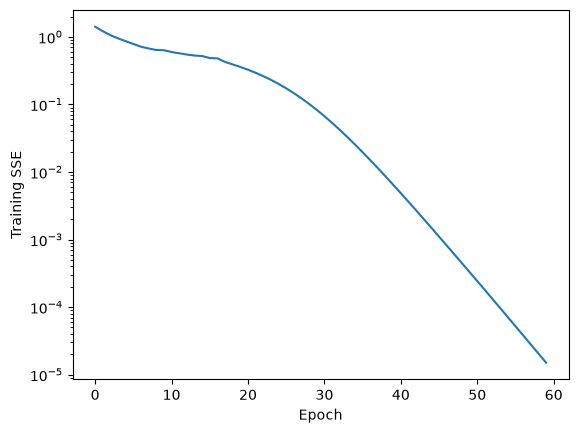

In [4]:
def forward_backward(x,y,W0,W1):
    pre=x@W0; hidden=np.maximum(0,pre); prediction=hidden@W1
    d2=prediction-y; d1=(d2@W1.T)*(pre>0)
    return .5*np.sum(d2*d2), x.T@d1, hidden.T@d2, prediction
loss,g0,g1,pred=forward_backward(X[:1],Y[:1],W0,W1)
print('Satu forward/backward:',loss,'G0:',g0,'G1:',g1)
# Tambahan: central difference jauh dari titik ReLU nol.
eps=1e-6; max_err=0.
for W,G in [(W0,g0),(W1,g1)]:
    for idx in np.ndindex(W.shape):
        old=W[idx]; W[idx]=old+eps; plus=forward_backward(X[:1],Y[:1],W0,W1)[0]
        W[idx]=old-eps; minus=forward_backward(X[:1],Y[:1],W0,W1)[0]; W[idx]=old
        max_err=max(max_err,abs((plus-minus)/(2*eps)-G[idx]))
assert max_err<1e-7
history=[]
for epoch in range(60):
    sse=0.
    for i in range(len(X)):
        loss,g0,g1,_=forward_backward(X[i:i+1],Y[i:i+1],W0,W1)
        sse+=2*loss
        W1-=.2*g1; W0-=.2*g0
    history.append(sse)
    if epoch%10==9: print('Epoch',epoch+1,'SSE',sse)
pred=np.maximum(0,X@W0)@W1
finite(W0,W1,pred)
print('Prediksi akhir:',pred.ravel(),'Target:',Y.ravel())
assert np.array_equal(pred>.5,Y>.5)
plt.semilogy(history); plt.xlabel('Epoch'); plt.ylabel('Training SSE'); plt.show()
record(final_sse=float(history[-1]),training_accuracy=float(np.mean((pred>.5)==Y)),gradient_max_error=max_err)

## Analisis output aktual — run tersimpan

Mode **quick**, eksekusi 2026-10-16T01:50:16.767120+07:00. Ringkasan ini dibuat dari output validator, bukan angka contoh dalam buku.

SSE epoch ke-60 1.5055623e-05; akurasi empat titik latihan 100%. Nilai ini cocok dengan contoh kecil buku hingga toleransi numerik. Tidak ada test independen sehingga 100% tidak boleh disebut akurasi generalisasi.

## Kesimpulan dan pembahasan pertanyaan

Output harus menunjukkan loss turun dan empat pola latihan terklasifikasi. Pemeriksaan gradien mendukung kesesuaian chain rule. Dataset hanya empat titik; akurasi latihan bukan hasil evaluasi independen.

**Apa fungsi transpose saat backprop?** Mengembalikan sinyal dari ruang output ke ruang input suatu matriks, dengan dimensi yang sesuai.

**Mengapa ReLU penting?** Ia membuat fungsi komposisi tidak bisa selalu diringkas menjadi satu transformasi linear.

**Apa yang terjadi pada neuron ReLU yang selalu negatif?** Gradiennya nol pada contoh-contoh itu sehingga jalur tersebut tidak belajar.

In [5]:
finite(*[v for v in METRICS.values() if isinstance(v, (int, float))])
print('VALIDATION_METRICS=' + json.dumps(METRICS, sort_keys=True))

VALIDATION_METRICS={"final_sse": 1.5055622665134859e-05, "gradient_max_error": 2.974809287792368e-11, "training_accuracy": 1.0}
